# UTS Machine Learning — Tugas 1: Regresi Durasi Pengiriman (P50 & P90)

Target: `durasi_jam`. Keluaran: `prediksi_regresi.csv` dengan kolom `id_paket,p50,p90` (p90 ≥ p50).
Metrik: *pinball loss* $L_q(y,\hat y)=\max\big(q(y-\hat y),\,(q-1)(y-\hat y)\big)$ untuk $q=0{,}5$ dan $q=0{,}9$.

**Alur:** audit data → rekayasa fitur → validasi *out-of-time* → model A (LightGBM kuantil) dan B (LightGBM L2 + kuantil residual) → gabungan → kalibrasi konformal P90 → analisis → prediksi akhir.

Letakkan `regresi_train_1/2/3.csv.gz` dan `regresi_test.csv.gz` di folder yang sama dengan notebook (atau di `data/`).

In [1]:
import sys, subprocess
try:
    import lightgbm
except ImportError:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','lightgbm'])
import os, glob, json, warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, lightgbm as lgb
import matplotlib; matplotlib.use('Agg') if False else None
import matplotlib.pyplot as plt
SEED=42; np.random.seed(SEED)
D = next(d for d in ['.','data','../data'] if os.path.exists(os.path.join(d,'regresi_test.csv.gz')))
tr = pd.concat([pd.read_csv(os.path.join(D,f'regresi_train_{i}.csv.gz')) for i in (1,2,3)], ignore_index=True)
te = pd.read_csv(os.path.join(D,'regresi_test.csv.gz'))
print(tr.shape, te.shape); print('kolom hanya di train:', sorted(set(tr.columns)-set(te.columns)))
print('rentang tanggal train', tr.tgl_pickup.min(), tr.tgl_pickup.max(), '| test', te.tgl_pickup.min(), te.tgl_pickup.max())

(250000, 77) (60000, 76)
kolom hanya di train: ['durasi_jam']
rentang tanggal train 2025-01-01 2025-08-31 | test 2025-09-01 2025-10-31


## 1. Audit data
Temuan penting: kolom `jumlah_scan` hanya terisi sebagai akibat pengiriman (bocor/leakage), `f30` berperilaku sebagai proksi waktu, ada kode sentinel pada `jarak_km`, `berat_kg` hilang tidak acak, dan ada outlier ekstrem.

kolom di test tapi tidak di train: []
count    250000.00
mean         77.84
std         207.66
min          11.60
25%          45.60
50%          61.70
75%          85.30
max       25452.00
y>1000 jam: 0.148%
jarak sentinel (<=0 atau >=9999): train 0.46%, test 0.51%
berat_kg hilang: train 5.56%, test 5.44%
berat hilang per layanan (train):
layanan
ekspres    0.025
hemat      0.026
kargo      0.329
reguler    0.025
kurir hanya di test: ['K13']


Statistik KS train vs test (terbesar):
jumlah_scan    0.916
f30            0.230
f17            0.110
f35            0.088
f41            0.010
f25            0.008
korelasi f30 dengan nomor hari: 0.271


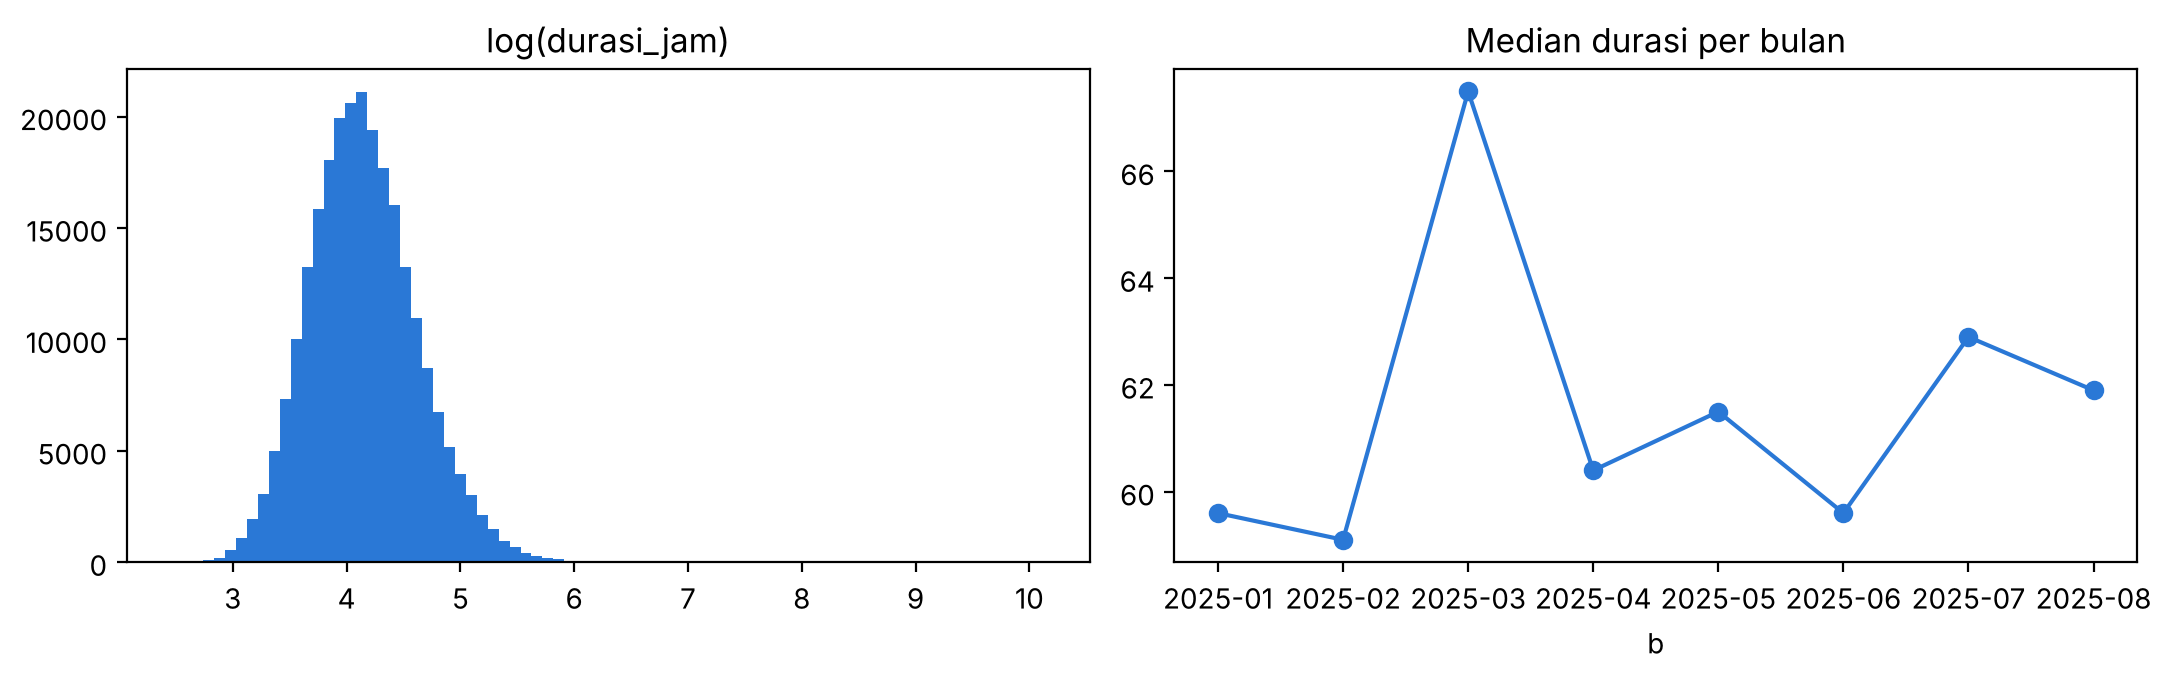

In [2]:
print('kolom di test tapi tidak di train:', sorted(set(te.columns)-set(tr.columns)))
print(tr.durasi_jam.describe().round(2).to_string())
print('y>1000 jam: %.3f%%' % (100*(tr.durasi_jam>1000).mean()))
print('jarak sentinel (<=0 atau >=9999): train %.2f%%, test %.2f%%' % (100*((tr.jarak_km<=0)|(tr.jarak_km>=9999)).mean(), 100*((te.jarak_km<=0)|(te.jarak_km>=9999)).mean()))
print('berat_kg hilang: train %.2f%%, test %.2f%%' % (100*tr.berat_kg.isna().mean(), 100*te.berat_kg.isna().mean()))
print('berat hilang per layanan (train):'); print(tr.groupby('layanan').berat_kg.apply(lambda s:s.isna().mean()).round(3).to_string())
print('kurir hanya di test:', sorted(set(te.mitra_kurir)-set(tr.mitra_kurir)))
from scipy.stats import ks_2samp
fc=[c for c in tr.columns if c.startswith('f') and c[1:].isdigit()]
ks=pd.Series({c:ks_2samp(tr[c].dropna(),te[c].dropna()).statistic for c in fc+['jumlah_scan'] if c in te}).sort_values(ascending=False)
print('Statistik KS train vs test (terbesar):'); print(ks.head(6).round(3).to_string())
tg=pd.to_datetime(tr.tgl_pickup)
print('korelasi f30 dengan nomor hari: %.3f' % np.corrcoef(tr.f30.fillna(tr.f30.median()), (tg-tg.min()).dt.days)[0,1])
fig,ax=plt.subplots(1,2,figsize=(11,3.5))
ax[0].hist(np.log(tr.durasi_jam),bins=80,color='#2a78d6'); ax[0].set_title('log(durasi_jam)'); 
tr.assign(b=tg.dt.to_period('M').astype(str)).groupby('b').durasi_jam.median().plot(ax=ax[1],color='#2a78d6',marker='o'); ax[1].set_title('Median durasi per bulan'); plt.tight_layout(); plt.show()

## 2. Rekayasa fitur
- `jarak_km` bersentinel diperbaiki deterministik lewat tabel median per pasangan (kota_asal, kota_tujuan) + penanda `jarak_rusak`.
- `berat_kg` hilang diisi `volume_liter/4` + penanda `berat_hilang` (hilang tidak acak).
- **Dibuang:** `jumlah_scan` (bocor, tidak ada saat prediksi), `f30` (proksi waktu), dan fitur kalender/jam (pola tanggal-kembar tidak stabil secara temporal).
- Kategori kardinalitas tinggi (`kota_tujuan`, dll.) memakai penanganan kategorikal native LightGBM; kurir baru di test jatuh ke kategori tak dikenal.

In [3]:
CAT=['layanan','mitra_kurir','hub_asal','kota_asal','pulau_tujuan','kota_tujuan']
def pair_table(*dfs):
    a=pd.concat(dfs); a=a[(a.jarak_km>0)&(a.jarak_km<9999)]; return a.groupby(['kota_asal','kota_tujuan']).jarak_km.median()
pairs=pair_table(tr,te)
FC=[f'f{i:02d}' for i in range(1,51) if i!=30]
def fe(df):
    X=pd.DataFrame(index=df.index)
    key=pd.MultiIndex.from_frame(df[['kota_asal','kota_tujuan']]); jf=pairs.reindex(key).to_numpy()
    bad=(df.jarak_km<=0)|(df.jarak_km>=9999)
    X['jarak_rusak']=bad.astype(int).to_numpy(); X['jarak_km']=np.where(bad,jf,df.jarak_km)
    X['berat_hilang']=df.berat_kg.isna().astype(int); X['berat_kg']=df.berat_kg.fillna(df.volume_liter/4.0)
    X['volume_liter']=df.volume_liter; X['kepadatan']=X.berat_kg/df.volume_liter.clip(lower=0.1)
    for c in ['jumlah_item','nilai_barang','asuransi','cod','alamat_skor','pengalaman_kurir_bulan','rating_penjual','umur_akun_penjual_hari','volume_penjual_30h','antrean_hub_asal','indeks_kemacetan','hujan_asal_mm','hujan_tujuan_mm']: X[c]=df[c]
    X['log_antrean']=np.log1p(df.antrean_hub_asal)
    for c in FC: X[c]=df[c]
    cats={c:sorted(set(tr[c])|set(te[c])) for c in CAT}
    for c in CAT: X[c]=pd.Categorical(df[c],categories=cats[c])
    return X
Xtr,Xte=fe(tr),fe(te); y=tr.durasi_jam.to_numpy(); ly=np.log(y); tgl=pd.to_datetime(tr.tgl_pickup)
print(Xtr.shape, Xte.shape, 'NaN jarak test:', Xte.jarak_km.isna().sum())

(250000, 75) (60000, 75) NaN jarak test: 1


## 3. Kerangka validasi
Data train berurutan waktu dan test berada **setelah** train, sehingga CV acak terlalu optimistis. Dipakai *expanding-window*: latih pada data sebelum tanggal $a$, uji pada $[a,b)$, tiga lipatan. Early stopping memakai 21 hari terakhir dari jendela latih.

In [4]:
FOLDS=[('2025-03-01','2025-05-01'),('2025-05-01','2025-07-01'),('2025-07-01','2025-09-01')]
P0=dict(learning_rate=0.04,num_leaves=15,min_data_in_leaf=800,feature_fraction=0.6,bagging_fraction=0.8,bagging_freq=1,lambda_l2=1.0,max_bin=127,cat_smooth=50,min_data_per_group=50,verbose=-1,seed=SEED,num_threads=4)
def pinball(y,p,q): d=y-p; return float(np.mean(np.maximum(q*d,(q-1)*d)))
def inner_time(t,days=21):
    cut=t.max()-pd.Timedelta(days=days); return np.where(t<cut)[0],np.where(t>=cut)[0]
def fit(Xa,ya,inner,**kw):
    ia,ib=inner; p=dict(P0,**kw)
    return lgb.train(p,lgb.Dataset(Xa.iloc[ia],ya[ia]),3000,valid_sets=[lgb.Dataset(Xa.iloc[ib],ya[ib])],callbacks=[lgb.early_stopping(50,verbose=False)])
def resid_q(mu,yl,grp):
    d=pd.DataFrame({'r':yl-mu,'g':np.asarray(grp)}); return d.groupby('g').r.quantile(.5).to_dict(),d.groupby('g').r.quantile(.9).to_dict(),float(d.r.quantile(.5)),float(d.r.quantile(.9))
def apply_q(mu,grp,t50,t90,g50,g90): return np.exp(mu+np.array([t50.get(g,g50) for g in grp])),np.exp(mu+np.array([t90.get(g,g90) for g in grp]))
def fit_AB(Xa,yl,t_a,lay_a,Xv,lay_v):
    inner=inner_time(t_a); out={}
    for q in (.5,.9): m=fit(Xa,yl,inner,objective='quantile',alpha=q); out[f'A{int(q*100)}']=np.exp(m.predict(Xv,num_iteration=m.best_iteration)); out[f'it{int(q*100)}']=m.best_iteration
    ia,ib=inner; yc=np.clip(yl,None,np.log(500.))
    mm=fit(Xa,yc,inner,objective='regression_l2')
    mu_in=mm.predict(Xa.iloc[ib],num_iteration=mm.best_iteration); t=resid_q(mu_in,yl[ib],np.asarray(lay_a)[ib])
    mu_v=mm.predict(Xv,num_iteration=mm.best_iteration); out['B50'],out['B90']=apply_q(mu_v,lay_v,*t); out['itL2']=mm.best_iteration
    return out
rows=[]
for k,(a,b) in enumerate(FOLDS):
    itr=np.where(tgl<a)[0]; iva=np.where((tgl>=a)&(tgl<b))[0]
    o=fit_AB(Xtr.iloc[itr],ly[itr],tgl.iloc[itr],tr.layanan.iloc[itr],Xtr.iloc[iva],tr.layanan.iloc[iva].to_numpy())
    d=pd.DataFrame({'idx':iva,'fold':k,'y':y[iva],'layanan':tr.layanan.iloc[iva].to_numpy(),'pulau':tr.pulau_tujuan.iloc[iva].to_numpy(),'kurir':tr.mitra_kurir.iloc[iva].to_numpy()})
    for c in ('A50','A90','B50','B90'): d[c]=o[c]
    rows.append(d); print('lipatan',k,'iterasi',o['it50'],o['it90'],o['itL2'],flush=True)
oof=pd.concat(rows,ignore_index=True)
oof['G50']=np.sqrt(oof.A50*oof.B50); oof['G90']=np.sqrt(oof.A90*oof.B90)

lipatan 0 iterasi 1766 568 705


lipatan 1 iterasi 1296 2481 819


lipatan 2 iterasi 1247 1259 849


### Baseline pembanding dan hasil model (rata-rata 3 lipatan temporal, satuan jam)

In [5]:
res=[]
for k,(a,b) in enumerate(FOLDS):
    trm=(tgl<a).to_numpy(); vm=((tgl>=a)&(tgl<b)).to_numpy(); g=tr[trm].groupby(['layanan','pulau_tujuan']).durasi_jam
    q5=g.quantile(.5).rename('v5'); q9=g.quantile(.9).rename('v9'); v=tr[vm][['layanan','pulau_tujuan']]
    p5=v.merge(q5,left_on=['layanan','pulau_tujuan'],right_index=True,how='left').v5.to_numpy(); p9=v.merge(q9,left_on=['layanan','pulau_tujuan'],right_index=True,how='left').v9.to_numpy()
    p5=np.nan_to_num(p5,nan=np.median(y)); p9=np.nan_to_num(p9,nan=np.quantile(y,.9)); yy=y[vm]
    res.append(dict(model='Baseline kuantil grup (layanan x pulau)',q50=pinball(yy,p5,.5),q90=pinball(yy,p9,.9),cov90=np.mean(yy<=p9)))
for nm,a5,a9 in [('A  LightGBM kuantil','A50','A90'),('B  LightGBM L2-log + kuantil residual','B50','B90'),('A+B rata-rata geometrik','G50','G90')]:
    for k in range(3):
        d=oof[oof.fold==k]; res.append(dict(model=nm,q50=pinball(d.y.values,d[a5].values,.5),q90=pinball(d.y.values,np.maximum(d[a5].values,d[a9].values),.9),cov90=np.mean(d.y<=d[a9])))
tab=pd.DataFrame(res).groupby('model',sort=False).mean().round(3); tab['jumlah']=(tab.q50+tab.q90).round(3); print(tab.to_string())

                                            q50     q90  cov90  jumlah
model                                                                 
Baseline kuantil grup (layanan x pulau)  13.608  12.109  0.881  25.717
A  LightGBM kuantil                      10.204  10.370  0.873  20.574
B  LightGBM L2-log + kuantil residual    10.237  10.316  0.865  20.553
A+B rata-rata geometrik                  10.196  10.298  0.871  20.494


### 3a. Dampak fitur bermasalah dan perbandingan dengan CV acak (soal a dan b)
Ablasi satu model LightGBM kuantil (P50 dan P90, parameter yang sama) pada tiga lipatan temporal. Varian: (1) fitur terpilih, (2) + `jumlah_scan` apa adanya, (3) + `jumlah_scan` yang di data uji diganti sebaran test, (4) + `f30`, (5) + fitur kalender/jam. Lalu fitur terpilih dan +`f30` diuji dengan **CV acak 3-lipatan** sebagai pembanding.

In [6]:
from sklearn.model_selection import KFold
Xall=Xtr.copy(); Xall['jumlah_scan']=tr.jumlah_scan.to_numpy(); Xall['f30']=tr.f30.to_numpy()
tg_=pd.to_datetime(tr.tgl_pickup); Xall['jam']=tr.jam_pickup.astype(int); Xall['dow']=tg_.dt.dayofweek; Xall['hari_bulan']=tg_.dt.day; Xall['twin']=(tg_.dt.day==tg_.dt.month).astype(int)
BASEC=list(Xtr.columns)
def sc(yv,p5,p9): return dict(q50=pinball(yv,p5,.5),q90=pinball(yv,p9,.9),cov90=float(np.mean(yv<=p9)))
def temporal_cols(cols,sim_scan=False):
    rs=[]
    for a,b in FOLDS:
        itr=np.where(tgl<a)[0]; iva=np.where((tgl>=a)&(tgl<b))[0]; inner=inner_time(tgl.iloc[itr]); ps=[]
        Xv=Xall.iloc[iva][cols].copy()
        if sim_scan: Xv['jumlah_scan']=np.random.default_rng(0).choice(te.jumlah_scan.to_numpy(),len(Xv))
        for q in (.5,.9):
            m=fit(Xall.iloc[itr][cols],ly[itr],inner,objective='quantile',alpha=q); ps.append(np.exp(m.predict(Xv,num_iteration=m.best_iteration)))
        rs.append(sc(y[iva],np.minimum(*ps),np.maximum(*ps)))
    return pd.DataFrame(rs).mean()
def random_cols(cols):
    rs=[]
    for k,(ia,iv) in enumerate(KFold(3,shuffle=True,random_state=SEED).split(Xall)):
        perm=np.random.default_rng(k).permutation(len(ia)); inner=(perm[int(.1*len(ia)):],perm[:int(.1*len(ia))]); ps=[]
        for q in (.5,.9):
            m=fit(Xall.iloc[ia][cols],ly[ia],inner,objective='quantile',alpha=q); ps.append(np.exp(m.predict(Xall.iloc[iv][cols],num_iteration=m.best_iteration)))
        rs.append(sc(y[iv],np.minimum(*ps),np.maximum(*ps)))
    return pd.DataFrame(rs).mean()
abl={}
abl['1. fitur terpilih (temporal)']=temporal_cols(BASEC)
abl['2. + jumlah_scan (temporal, apa adanya)']=temporal_cols(BASEC+['jumlah_scan'])
abl['3. + jumlah_scan, nilai valid diganti sebaran test']=temporal_cols(BASEC+['jumlah_scan'],sim_scan=True)
abl['4. + f30 (temporal)']=temporal_cols(BASEC+['f30'])
abl['5. + fitur kalender/jam (temporal)']=temporal_cols(BASEC+['jam','dow','hari_bulan','twin'])
abl['6. fitur terpilih, CV acak']=random_cols(BASEC)
abl['7. + f30, CV acak']=random_cols(BASEC+['f30'])
T=pd.DataFrame(abl).T.round(3); T['jumlah']=(T.q50+T.q90).round(3); print(T.to_string())

                                                       q50     q90  cov90  jumlah
1. fitur terpilih (temporal)                        10.204  10.370  0.873  20.574
2. + jumlah_scan (temporal, apa adanya)              8.863   8.904  0.876  17.767
3. + jumlah_scan, nilai valid diganti sebaran test  13.928  19.532  0.429  33.460
4. + f30 (temporal)                                 10.214  10.357  0.874  20.571
5. + fitur kalender/jam (temporal)                  10.420  10.463  0.864  20.883
6. fitur terpilih, CV acak                           9.909  10.172  0.894  20.081
7. + f30, CV acak                                    9.911  10.166  0.893  20.077


**Kesimpulan ablasi:**
- `jumlah_scan` tampak sangat membantu pada validasi (jumlah 20,57 → 17,77) tetapi hanya karena fitur ini terisi akibat pengiriman. Jika nilainya di data validasi diganti sebaran test (yang tidak informatif), model langsung ambruk: pinball 33,46 dan cakupan P90 hanya 0,43. Fitur ini **dibuang**.
- `f30` tidak menambah akurasi (20,571 vs 20,574) pada validasi temporal maupun acak; perannya hanya sebagai proksi waktu sehingga **dibuang**.
- Fitur kalender/jam sedikit memperburuk (20,88) pada validasi temporal; polanya tidak stabil antar waktu, **dibuang**.
- **CV acak terlalu optimistis**: jumlah 20,08 dan cakupan 0,894, dibanding 20,57 dan 0,873 pada validasi temporal. Karena test berada setelah train, skema temporal dipakai untuk semua pemilihan.

### 3b. Model linier dengan transformasi target (Ridge pada $\\log y$) dan simulasi kurir yang hanya ada di test (soal c dan d)

In [7]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
SK=['jarak_km','berat_kg','volume_liter','nilai_barang','umur_akun_penjual_hari','volume_penjual_30h','antrean_hub_asal']
NUMC=[c for c in Xtr.columns if c not in CAT]
def rtf(X_):
    Z=X_.copy()
    for c in SK: Z[c]=np.log1p(Z[c].astype(float).clip(lower=0))
    return Z
def ridge_fit(Xa,ya):
    ct=ColumnTransformer([('n',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),NUMC),('c',OneHotEncoder(handle_unknown='ignore',min_frequency=20),CAT)])
    return make_pipeline(ct,Ridge(alpha=30.0)).fit(rtf(Xa),ya)
rs=[]
for k,(a,b) in enumerate(FOLDS):
    itr=np.where(tgl<a)[0]; iva=np.where((tgl>=a)&(tgl<b))[0]
    mr=ridge_fit(Xtr.iloc[itr],np.clip(ly[itr],None,np.log(500.))); mu_t=mr.predict(rtf(Xtr.iloc[itr])); mu_v=mr.predict(rtf(Xtr.iloc[iva]))
    t50,t90,g50,g90=resid_q(mu_t,ly[itr],tr.layanan.iloc[itr]); r5,r9=apply_q(mu_v,tr.layanan.iloc[iva].to_numpy(),t50,t90,g50,g90)
    rs.append(sc(y[iva],np.minimum(r5,r9),np.maximum(r5,r9)))
R=pd.DataFrame(rs).mean().round(3); R['jumlah']=round(R.q50+R.q90,3); print('Ridge log-linear + kuantil residual per layanan (rata-rata 3 lipatan):'); print(R.to_string())
a,b=FOLDS[2]; itr=np.where(tgl<a)[0]; iva=np.where((tgl>=a)&(tgl<b))[0]
kur=tr.mitra_kurir.iloc[iva].value_counts().index[0]; itr_x=itr[(tr.mitra_kurir.iloc[itr]!=kur).to_numpy()]; sel=(tr.mitra_kurir.iloc[iva]==kur).to_numpy(); out=[]
for nm,ii in [('kurir %s dikenal'%kur,itr),('kurir %s TIDAK ada di latihan (seperti K13)'%kur,itr_x)]:
    inner=inner_time(tgl.iloc[ii]); ps=[]
    for q in (.5,.9):
        m=fit(Xtr.iloc[ii],ly[ii],inner,objective='quantile',alpha=q); ps.append(np.exp(m.predict(Xtr.iloc[iva],num_iteration=m.best_iteration)))
    d=sc(y[iva][sel],np.minimum(*ps)[sel],np.maximum(*ps)[sel]); d['skenario']=nm; out.append(d)
print(); print(pd.DataFrame(out).set_index('skenario').round(3).to_string()); print('kurir yang hanya ada di test:',sorted(set(te.mitra_kurir)-set(tr.mitra_kurir)),'| baris test',int(te.mitra_kurir.isin(set(te.mitra_kurir)-set(tr.mitra_kurir)).sum()))

Ridge log-linear + kuantil residual per layanan (rata-rata 3 lipatan):
q50       10.778
q90       10.511
cov90      0.885
jumlah    21.289



                                                 q50     q90  cov90
skenario                                                           
kurir K01 dikenal                             11.287  13.296  0.906
kurir K01 TIDAK ada di latihan (seperti K13)  11.508  13.329  0.917
kurir yang hanya ada di test: ['K13'] | baris test 2342


**Ridge (model linier + transformasi log target)** lebih lemah daripada LightGBM (jumlah pinball 21,29 vs 20,57), tetapi cakupan P90 (0,885) lebih dekat ke 0,90. Model linier dipakai sebagai pembanding dan bukti bahwa interaksi non-linier memang berguna.

**Simulasi kurir baru:** satu kurir terbesar dikeluarkan dari latihan sehingga tampil seperti K13 (hanya ada di test, 2.342 baris). Kesalahan P50 naik tipis (11,29 → 11,51) dan cakupan P90 tetap terjaga (0,92). LightGBM menangani kategori tak dikenal dengan baik; nilai ini diukur pada satu kurir sehingga hanya indikasi.

## 4. Kalibrasi konformal untuk P90
Cakupan P90 mentah di bawah 0,90 (pergeseran distribusi antar waktu). Kalibrasi *split conformal* bergeser aditif di ruang log: $\hat q_{0.9}^{\text{kal}}=\hat q_{0.9}\,e^{c}$, dengan $c$ = kuantil-0,9 dari $\log y-\log\hat q_{0.9}$ pada data *out-of-time*. Diuji dengan *leave-one-fold-out*.

In [8]:
s=np.log(oof.y)-np.log(oof.G90); out=[]
for k in range(3):
    c=np.quantile(s[oof.fold!=k],.9); d=oof[oof.fold==k]; p9=d.G90*np.exp(c)
    out.append(dict(lipatan=k,geser_c=round(c,3),cakupan_mentah=round(float((d.y<=d.G90).mean()),3),cakupan_kalibrasi=round(float((d.y<=p9).mean()),3),pinball_mentah=round(pinball(d.y.values,d.G90.values,.9),3),pinball_kalibrasi=round(pinball(d.y.values,p9.values,.9),3)))
print(pd.DataFrame(out).to_string(index=False))
C_SHIFT=float(np.quantile(s,.9)); print('c final (gabungan 3 lipatan):',round(C_SHIFT,4))

 lipatan  geser_c  cakupan_mentah  cakupan_kalibrasi  pinball_mentah  pinball_kalibrasi
       0    0.012           0.826              0.834          10.069              9.991
       1    0.076           0.907              0.939           9.562              9.694
       2    0.058           0.880              0.912          11.263             11.217
c final (gabungan 3 lipatan): 0.0486


## 5. Analisis galat

               n  median_y     q50     q90  cakupan90
layanan                                              
ekspres  28680.0      39.6   6.100   6.312      0.902
hemat    63784.0      74.4  12.705  12.169      0.900
kargo    19248.0      79.1  10.994  10.425      0.904
reguler  80747.0      58.8   9.485  10.077      0.899

                           n  median_y     q50     q90  cakupan90
pulau                                                            
Bali-Nusa Tenggara    7375.0      65.8  10.736   9.254      0.887
Jawa                128316.0      56.8   8.393   8.970      0.905
Kalimantan           10829.0      91.2  15.700  14.583      0.881
Maluku                3699.0     116.5  21.424  20.889      0.886
Papua                 3559.0     160.8  24.541  18.771      0.872
Sulawesi             12694.0      89.5  16.159  15.997      0.887
Sumatera             25987.0      64.4  10.196   9.510      0.899



             n  median_y     q50     q90  cakupan90
kurir                                              
K01    27117.0     58.70  10.702  11.749      0.906
K02    23090.0     66.90  11.392  12.070      0.905
K03    21225.0     65.70  10.210  10.056      0.905
K04    19056.0     60.30   9.147   8.879      0.911
K05    17364.0     63.55   9.042   8.122      0.906
K06    15388.0     63.60  11.998  13.407      0.909
K07    15304.0     67.00  12.836  12.420      0.825
K08    13453.0     53.10   7.728   7.012      0.905
K09    11467.0     59.30   9.477   9.578      0.901
K10    11687.0     63.70   9.531   9.051      0.905
K11     9547.0     61.90   8.582   7.736      0.910
K12     7761.0     63.50   9.601   9.061      0.906


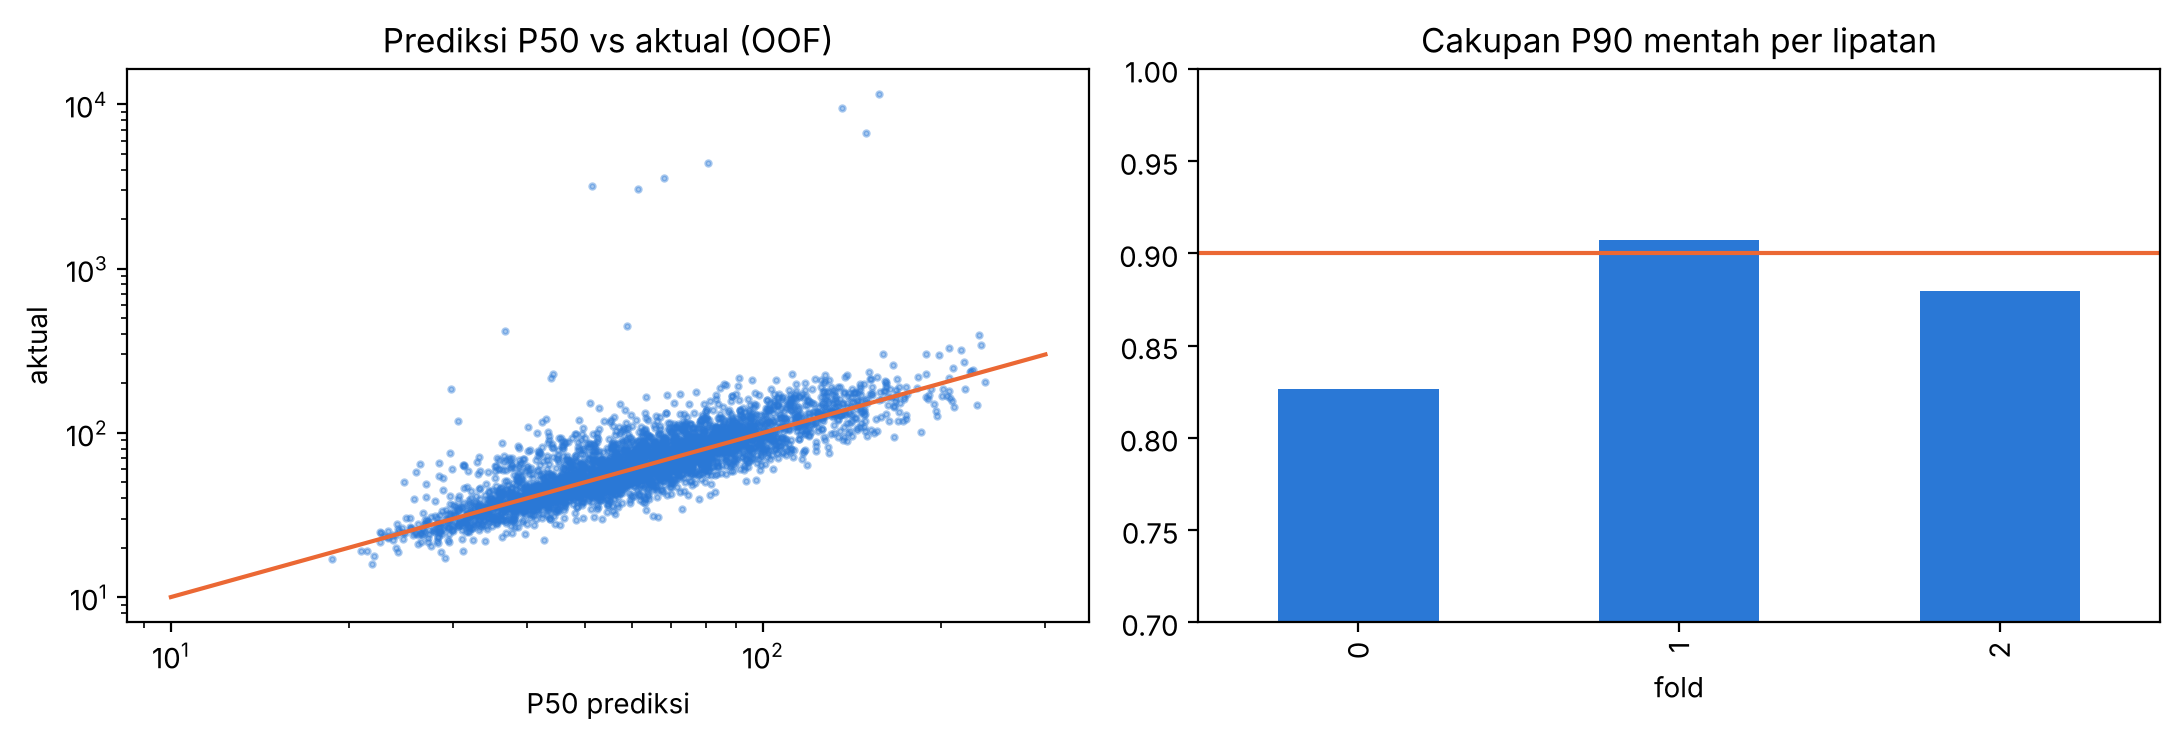

In [9]:
oof['P90k']=oof.G90*np.exp(C_SHIFT)
def grp(col):
    return oof.groupby(col).apply(lambda d:pd.Series(dict(n=len(d),median_y=d.y.median(),q50=pinball(d.y.values,d.G50.values,.5),q90=pinball(d.y.values,d.P90k.values,.9),cakupan90=(d.y<=d.P90k).mean()))).round(3)
print(grp('layanan').to_string()); print(); print(grp('pulau').to_string()); print(); print(grp('kurir').to_string())
fig,ax=plt.subplots(1,2,figsize=(11,3.8))
m=np.random.default_rng(0).choice(len(oof),4000,replace=False); d=oof.iloc[m]
ax[0].scatter(d.G50,d.y,s=4,alpha=.4,color='#2a78d6'); ax[0].plot([10,300],[10,300],color='#eb6834'); ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('P50 prediksi'); ax[0].set_ylabel('aktual'); ax[0].set_title('Prediksi P50 vs aktual (OOF)')
oof.groupby('fold').apply(lambda d:(d.y<=d.G90).mean()).plot.bar(ax=ax[1],color='#2a78d6'); ax[1].axhline(.9,color='#eb6834'); ax[1].set_ylim(.7,1); ax[1].set_title('Cakupan P90 mentah per lipatan'); plt.tight_layout(); plt.show()

**Per kurir:** cakupan P90 stabil ±0,90 untuk 11 dari 12 kurir; **K07 menyimpang (0,825)**, artinya P90 untuk kurir ini terlalu optimis. Kesalahan P50 terendah pada K08 dan tertinggi pada K07 dan K06. Kalibrasi konformal global tidak memperbaiki perbedaan antar-kurir; kalibrasi per kurir bisa menjadi perbaikan lanjutan.

## 6. Model akhir: latih pada seluruh train, prediksi test

In [10]:
o=fit_AB(Xtr,ly,tgl,tr.layanan,Xte,te.layanan.to_numpy())
p50=np.sqrt(o['A50']*o['B50']); p90=np.sqrt(o['A90']*o['B90'])*np.exp(C_SHIFT)
p50,p90=np.minimum(p50,p90),np.maximum(p50,p90)
sub=pd.DataFrame({'id_paket':te.id_paket,'p50':p50.round(3),'p90':p90.round(3)})
sub['p90']=np.maximum(sub.p90,sub.p50)
sub.to_csv('prediksi_regresi.csv',index=False)
chk=pd.read_csv('prediksi_regresi.csv')
assert list(chk.columns)==['id_paket','p50','p90'] and len(chk)==len(te) and chk.id_paket.is_unique and set(chk.id_paket)==set(te.id_paket)
assert chk[['p50','p90']].notna().all().all() and (chk.p90>=chk.p50).all() and (chk.p50>0).all()
print('prediksi_regresi.csv OK', chk.shape); print(chk.describe().round(2).to_string())

prediksi_regresi.csv OK (60000, 3)
            p50       p90
count  60000.00  60000.00
mean      70.35     99.63
std       32.63     46.61
min       17.42     28.00
25%       47.74     67.97
50%       62.86     88.25
75%       84.41    118.01
max      363.48    526.78


## 7. Interpretasi: kepentingan fitur dan SHAP (LightGBM `pred_contrib`)

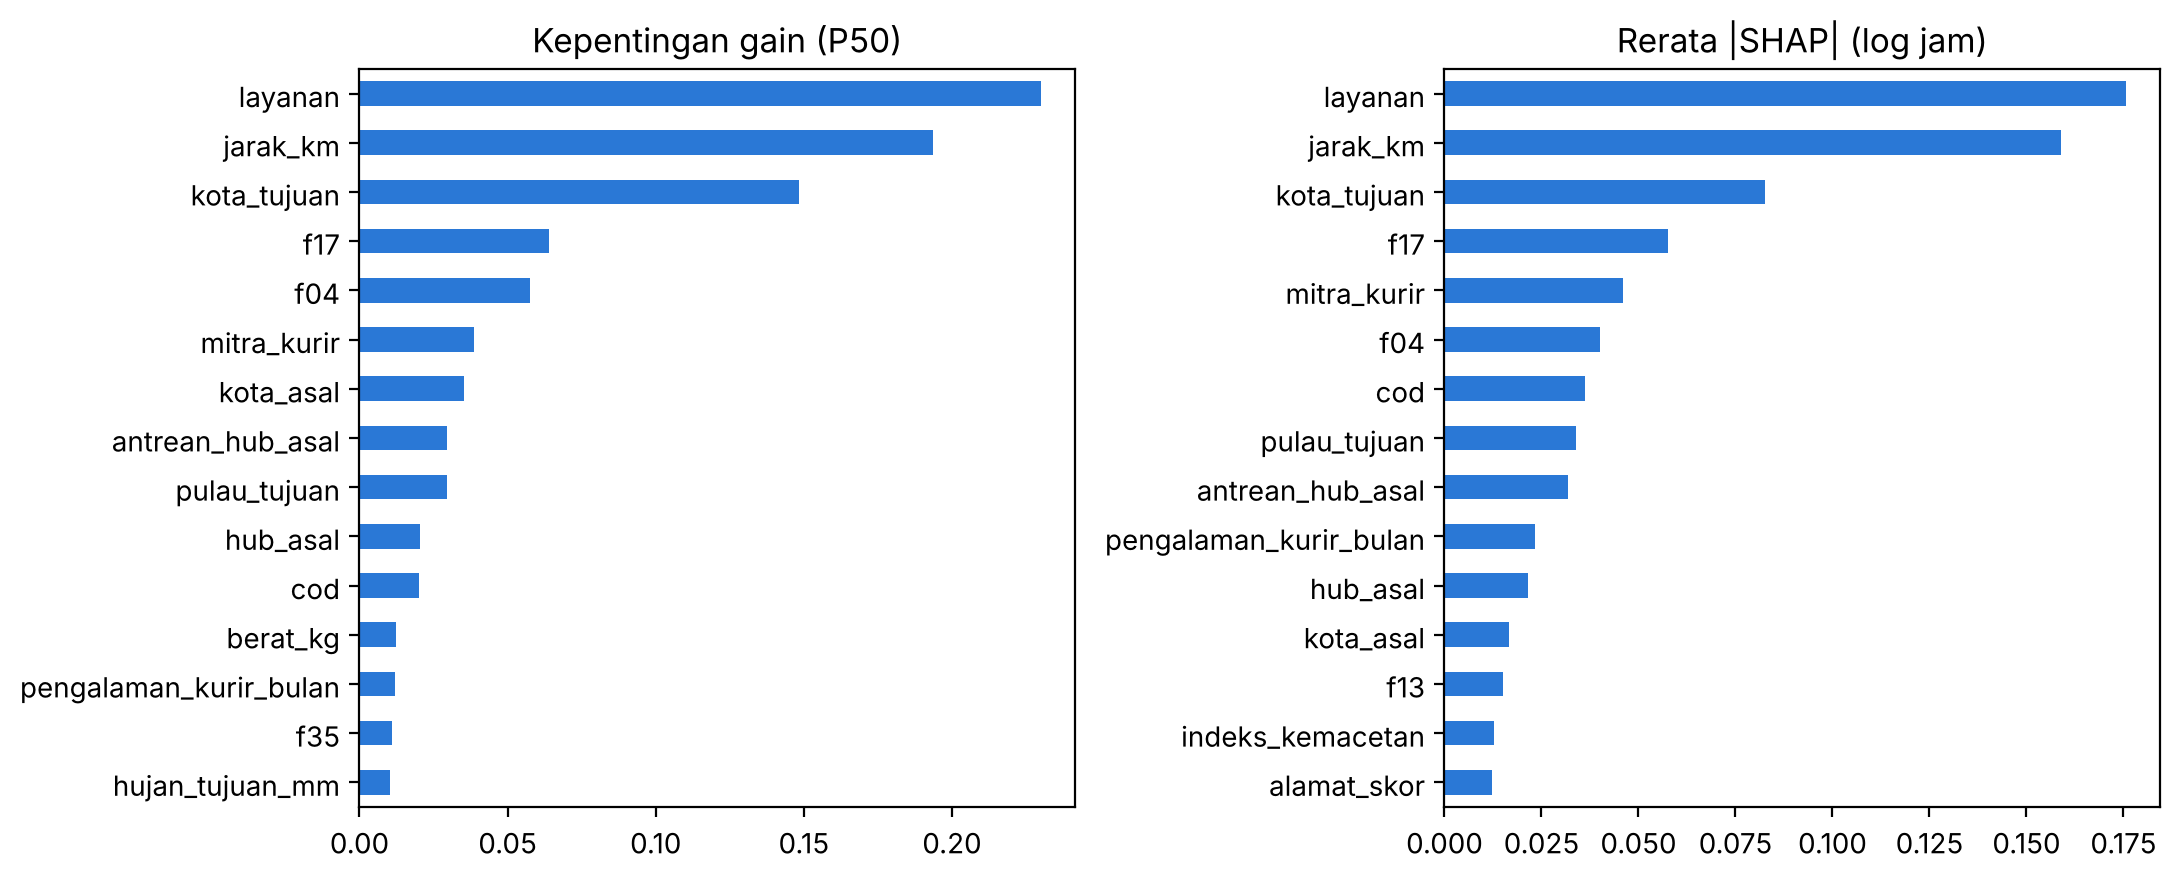

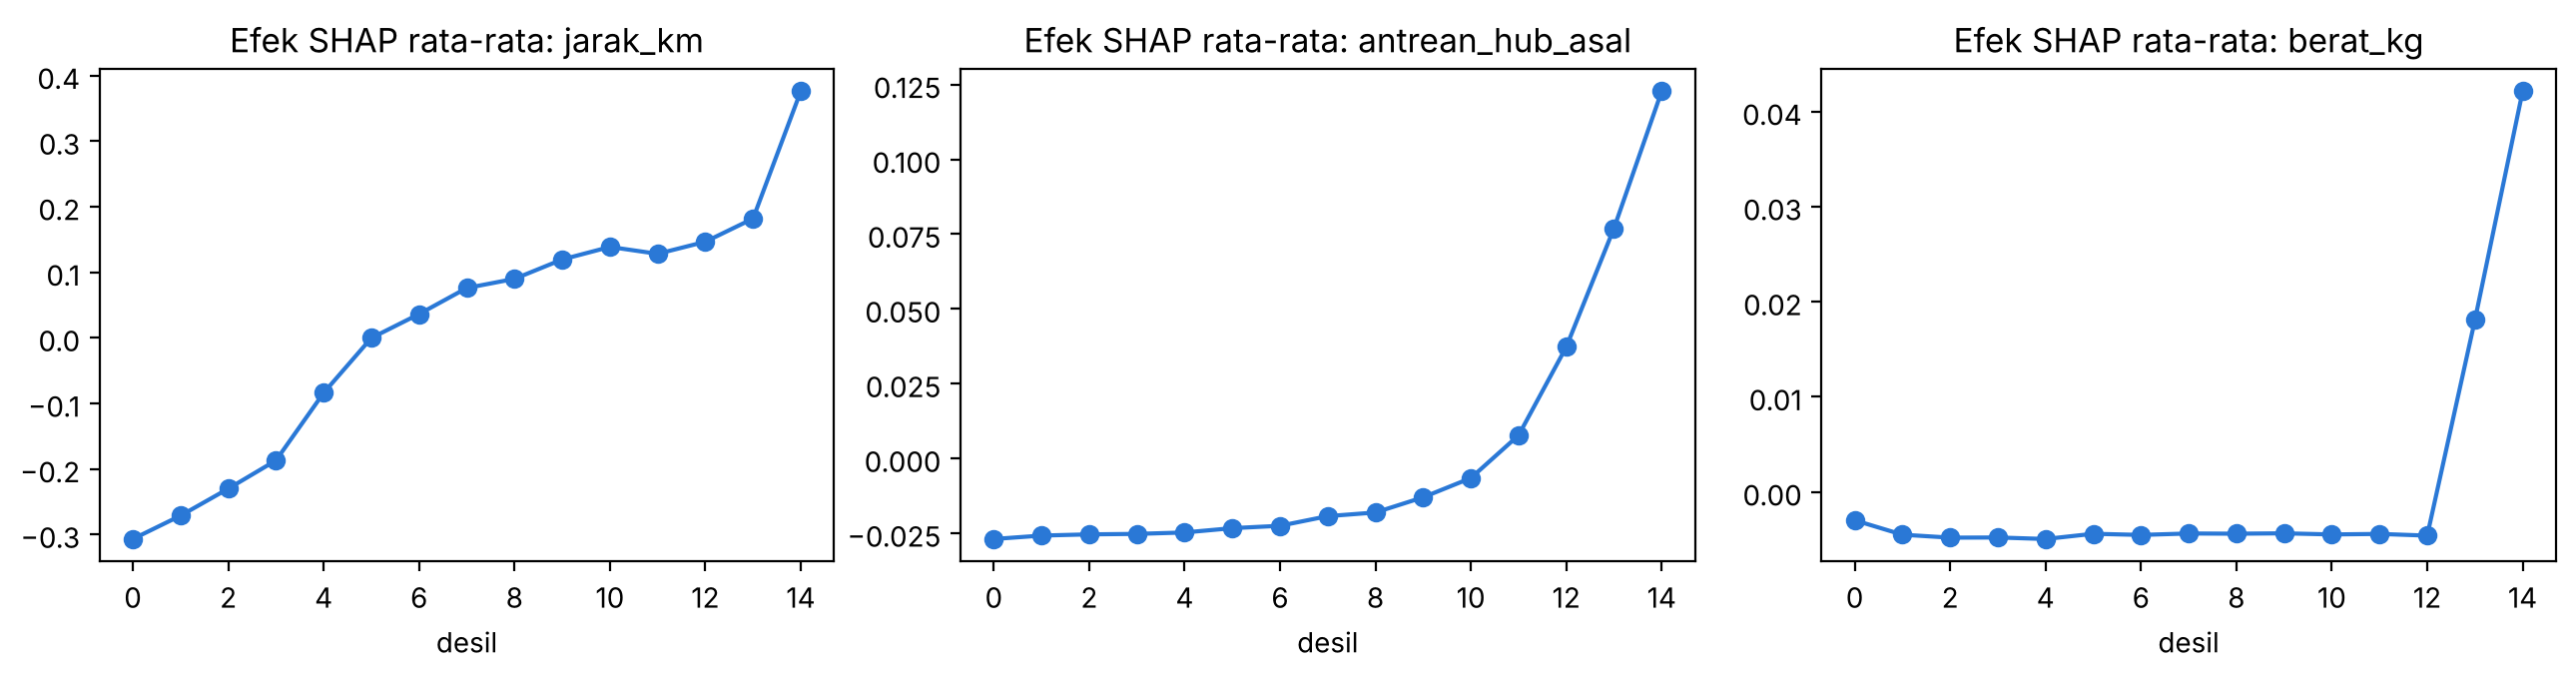

In [11]:
m50=fit(Xtr,ly,inner_time(tgl),objective='quantile',alpha=.5)
imp=pd.Series(m50.feature_importance('gain'),index=Xtr.columns).sort_values(ascending=False); imp=imp/imp.sum()
smp=Xtr.sample(3000,random_state=SEED); sv=m50.predict(smp,pred_contrib=True,num_iteration=m50.best_iteration)[:,:-1]
shap_abs=pd.Series(np.abs(sv).mean(0),index=Xtr.columns).sort_values(ascending=False)
fig,ax=plt.subplots(1,2,figsize=(11,4.5)); imp.head(15)[::-1].plot.barh(ax=ax[0],color='#2a78d6'); ax[0].set_title('Kepentingan gain (P50)')
shap_abs.head(15)[::-1].plot.barh(ax=ax[1],color='#2a78d6'); ax[1].set_title('Rerata |SHAP| (log jam)'); plt.tight_layout(); plt.show()
fig,ax=plt.subplots(1,3,figsize=(13,3.5))
for a_,c in zip(ax,['jarak_km','antrean_hub_asal','berat_kg']):
    b=pd.qcut(smp[c],15,duplicates='drop'); g=pd.Series(sv[:,list(Xtr.columns).index(c)]).groupby(b.values).mean(); a_.plot(range(len(g)),g.values,marker='o',color='#2a78d6'); a_.set_title('Efek SHAP rata-rata: '+c); a_.set_xlabel('desil'); 
plt.tight_layout(); plt.show()

## 8. Ringkasan
- Fitur bocor (`jumlah_scan`) dan proksi waktu (`f30`) **tidak dipakai**; validasi *out-of-time* mencerminkan kondisi test.
- Model final: rata-rata geometrik LightGBM kuantil (A) dan LightGBM L2-log dengan kuantil residual per layanan (B); P90 dikalibrasi konformal.
- Keterbatasan: cakupan P90 antar lipatan bervariasi (pergeseran distribusi); kurir yang hanya ada di test (K13) ditangani sebagai kategori tak dikenal; outlier ekstrem (>1000 jam, ±0,15%) tidak dapat diprediksi.
- Keluaran: `prediksi_regresi.csv`.